In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
sys.path.insert(0, '../../../src/')
import DoubleLayerWithHoles as DL
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc
import Geometries as geo

In [2]:
inside_solution = pd.read_csv('EigenvaluesEigenvectorsInsideSol_Dahne_MPI.csv', low_memory=False) 

In [3]:
inside_solution

,Eigenvalues,Eigenvectors0,Inside0,Inside1,Solution0,Eigenvalues.1,Eigenvectors0.1,Inside0.1,Inside1.1,Solution0.1,Eigenvalues_higher_precision,Eigenvectors_higher_precision0,Inside_higher_precision0,Inside_higher_precision1,Solution_higher_precision0,nodal_line0,nodal_line1
0,(2.4419625286915596-6.4372781057318155e-12j),(-0.0001622332315391066+3.236219306984366e-05j),0.00000,-1.99875,(5.634708360757327e-07+5.572648121495729e-07j),(3.8116594409985494-1.4382789749217618e-08j),(-0.009270931755724071+0.010746624391356908j),0.00000,-1.99875,(6.354490821956207e-05+5.97261302197824e-05j),(3.8116594409985494-1.4382789749217618e-08j),(-0.009270931755724071+0.010746624391356908j),-0.157304,-1.992522,(6.4191562420126e-05+6.059755731861044e-05j),-0.297130,-0.612142
1,NaN,(-0.00015921263779229672+3.943918933258377e-05j),-0.41000,-1.94750,(3.4916823228520592e-06+3.467514761890678e-06j),NaN,(-0.00935979859010952+0.01087941177604089j),-0.41000,-1.94750,(0.0004676341647874764+0.000440293188903847j),NaN,(-0.00935979859010952+0.01087941177604089j),-0.148565,-1.992522,(9.817214121485458e-05+9.182530449023535e-05j),-0.299421,-0.611739
2,NaN,(-0.00015256047149851614+5.4938836968584555e-05j),-0.35875,-1.94750,(7.394333832599565e-06+7.315562166484676e-06j),NaN,(-0.009552159810407008+0.011170479738882529j),-0.35875,-1.94750,(0.000955780938009505+0.0008984900159767443j),NaN,(-0.009552159810407008+0.011170479738882529j),-0.139826,-1.992522,(0.00013033769579511544+0.00012126471306259448j),-0.305870,-0.610570
3,NaN,(-0.00014717355408732548+6.740738990923097e-05j),-0.30750,-1.94750,(1.1150462046018223e-05+1.1014573862534356e-05j),NaN,(-0.00970497322556356+0.011404576148326219j),-0.30750,-1.94750,(0.0013936966619054734+0.0013092557336832986j),NaN,(-0.00970497322556356+0.011404576148326219j),-0.131087,-1.992522,(0.00016058589731312786+0.00014910675529780648j),-0.314609,-0.608514
4,NaN,(-0.00013576622485439403+9.35723163726106e-05j),-0.25625,-1.94750,(1.4671698832143377e-05+1.4507605753160172e-05j),NaN,(-0.01002002272915975+0.011895725105078747j),-0.25625,-1.94750,(0.0017754016248969855+0.0016685840515753315j),NaN,(-0.01002002272915975+0.011895725105078747j),-0.122348,-1.992522,(0.000188348437100225+0.00017664808925705808j),-0.323348,-0.605852
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149370,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.122348,1.992522,(0.00018834806658450014+0.00017664830461099415j),NaN,NaN
149371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.131087,1.992522,(0.00016058553799458333+0.00014910695447186567j),NaN,NaN
149372,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.139826,1.992522,(0.00013033734784852593+0.00012126489481144309j),NaN,NaN
149373,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.148565,1.992522,(9.817180543509902e-05+9.182546772340885e-05j),NaN,NaN


In [4]:
xy_inside = inside_solution[['Inside0', 'Inside1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [5]:
sol = inside_solution['Solution0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [6]:
faces = np.array([55,55,55,55,55])
n = 2*faces
alpha = (1-np.sqrt(3/5))/2

a_big_ell = 2
b_big_ell = 2
xm_big_ell = 0
ym_big_ell = 0
rot_big_ell = 0
n_ellipses = 6

# Parameters for the inner ellpses
a_small_ell = 0.15584574005610
b_small_ell = 0.39126299243500
distance_small_ell = 1.07497307444190
angles_small_ell = np.linspace(0,2*np.pi, n_ellipses, endpoint=False)
xm_small_ell = distance_small_ell*np.cos(angles_small_ell)
ym_small_ell = distance_small_ell*np.sin(angles_small_ell)
rot_small_ell = angles_small_ell

# Parameters for the inner hypotrochoid
xa_hyp = 0.6
xi_hyp = 0.5
A_hyp = n_ellipses
r_hyp = (xa_hyp+xi_hyp)/(2*(A_hyp-1))
R_hyp = A_hyp*r_hyp
a_hyp = (A_hyp-1)*(xa_hyp-xi_hyp)/(xa_hyp+xi_hyp)
xm_hyp = 0
ym_hyp = 0
rot_hyp = 0

vi, collocation_nodes = geo.create_6_ellipses(a_big_ell,b_big_ell,0,0,0,a_small_ell,b_small_ell,distance_small_ell,n_ellipses,n[0],alpha)


In [7]:
hypotrochoid = DL.create_hypotrochoid(R_hyp,r_hyp,a_hyp,xm_hyp,ym_hyp,rot_hyp,n[0])

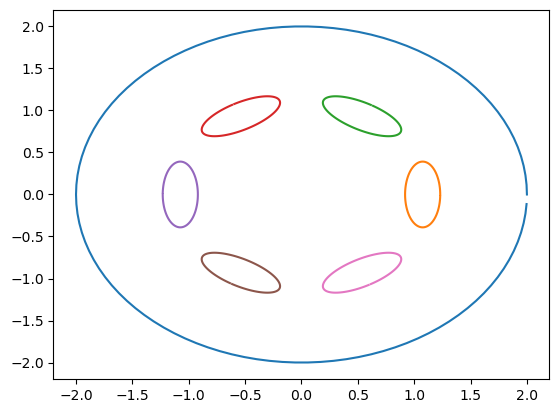

In [8]:
for i in range(vi.shape[0]):
    plt.plot(vi[i][0,:], vi[i][1,:])

In [9]:
#for i in range(vi_first_eig.shape[0]):
vi_closed_curve = np.dstack((vi,vi[:,:,0:1]))

In [10]:
hypotrochoid_closed_curve =  np.hstack((hypotrochoid,hypotrochoid[:,-2:-1]))

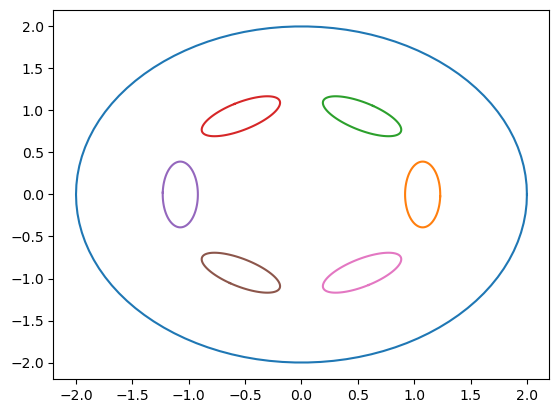

In [11]:
for i in range(vi_closed_curve.shape[0]):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:])

In [12]:
def ray_tracing_in_holes(boundary, xmid, ymid, radius):
    """
    Routine to find all the points of a square on an equidistant grid, that lie within the given domain without the given holes.

    Parameters
    ----------
    boundary : numpy.ndarray
        Array containing the vertices and midpoints for each of the approximated boundaries.
    xmid : numpy.ndarray
        x-Positions of all points that should be checked to be inside the given domain without holes.
    ymid : numpy.ndarray
        y-Positions of all points that should be checked to be inside the given domain without holes.
    radius : float
        Adds or subtracts a margin around a path to make the enclosed area slightly larger or smaller.

    Returns
    -------
    xy_inside : numpy.ndarray
        Numpy array containing all points that lie inside of the given domain without the holes.
    """
    # Create a path for the boundary of the holes
    p = [path.Path(boundary[i].T) for i in range(boundary.shape[0])]    
    # Create the mesh of the square to be checked, whether they are inside or outside of the domain with holes.
    mesh = np.stack((xmid,ymid),axis = 1)
    # Check whether the mesh is inside or outside of the outer boundary of the domain (without holes).
    inside = np.array([p[i].contains_points(mesh,radius=radius) for i in range(boundary.shape[0])])
    inside_any = np.any(inside, axis=0)
    return inside_any

In [13]:
eigenvalues = inside_solution['Eigenvalues'][0]
eigenvalues

'(2.4419625286915596-6.4372781057318155e-12j)'

In [14]:
(2.4419625286915596-6.4372781057318155e-12j) * (2.4419625286915596-6.4372781057318155e-12j)

(5.963180991533676-3.143918384192735e-11j)

In [15]:
import matplotlib.colors as mcolors

# Erstelle eine benutzerdefinierte Colormap
def custom_colormap():
    # Definiere die Grenzen für die Colormap
    bounds = [-0.01, 0, 0.1]
    # Erstelle eine Colormap basierend auf 'plasma'
    cmap = plt.get_cmap('plasma', len(bounds) - 1)
    
    # Erstelle eine normierte Colormap für logarithmische Skalierung
    norm = mcolors.BoundaryNorm(bounds, cmap.N)
    
    return cmap, norm

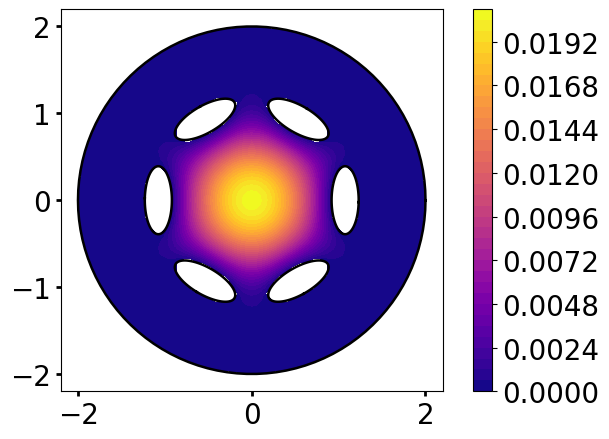

In [16]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)
vmin_sol=np.sort(real_sol)[0]
vmax_sol=np.sort(real_sol)[-1]

# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)
mask1 = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), xmid, ymid, 0.0)
mask2 = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), xmid, ymid, 0.0)
mask3 = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), xmid, ymid, 0.0)
mask4 = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), xmid, ymid, 0.0)
mask5 = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), xmid, ymid, 0.0)
mask6 = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), xmid, ymid, 0.0)
mask7 = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), xmid, ymid, 0.0)

mask1_inv = ~mask1
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7
triang.set_mask(mask)

# Kontur-Plot
plt.rcParams.update({'font.size':20})
plt.tick_params(axis='both', width=2)
plt.tricontourf(triang, real_sol, cmap='plasma',levels= 40, vmin=vmin_sol, vmax=vmax_sol)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=20)
plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1.8)

for i in range(n_ellipses+1):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:], color='black', linewidth = 1.8)

plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)

plt.axis('square')

plt.tight_layout()

plt.show()

In [17]:
eigenvalues = inside_solution['Eigenvalues_higher_precision'][0]
eigenvalues

'(3.8116594409985494-1.4382789749217618e-08j)'

In [18]:
(3.8116594409985494-1.4382789749217618e-08j) * (3.8116594409985494-1.4382789749217618e-08j)

(14.528747694153374-1.0964459267100498e-07j)

In [19]:
xy_inside = inside_solution[['Inside_higher_precision0', 'Inside_higher_precision1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [20]:
sol = inside_solution['Solution_higher_precision0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [21]:
big_ellipse = DL.create_ellipse(a_big_ell,b_big_ell,xm_big_ell,ym_big_ell,rot_big_ell,n[0])

In [22]:
small_ellipses = np.array([np.flip(DL.create_ellipse(a_small_ell,b_small_ell,xm_small_ell[i],ym_small_ell[i],rot_small_ell[i],n[0]),1) for i in range(n_ellipses)])

In [23]:
radius = 0.01

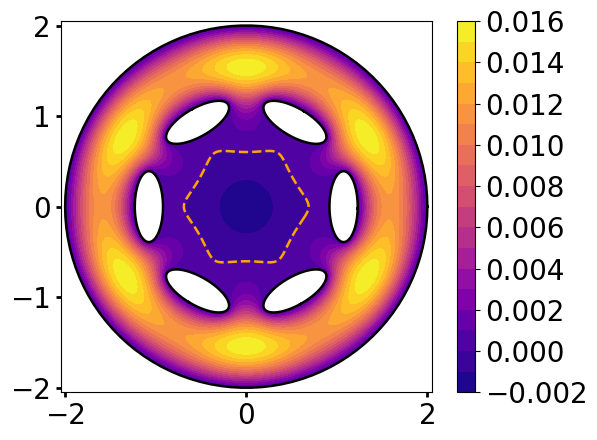

In [42]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)

big_ellipse_append = np.concatenate((big_ellipse, big_ellipse[:,0].reshape(2,1)), axis=1)
small_ellipses_append = np.concatenate((small_ellipses, small_ellipses[:,:,0].reshape(small_ellipses.shape[0],2,1)), axis=2)
vmin_sol=np.sort(real_sol)[0]
vmax_sol=np.sort(real_sol)[-1]

# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
x_boundary = x_inside[triang.triangles]
y_boundary = y_inside[triang.triangles]
x_boundary_flatten = x_boundary.flatten()
y_boundary_flatten = y_boundary.flatten()
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)

mask1_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), x_boundary_flatten, y_boundary_flatten, 0.01)
mask2_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask3_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask4_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask5_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask6_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask7_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), x_boundary_flatten, y_boundary_flatten, -0.01)

mask1_reshape = mask1_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask2_reshape = mask2_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask3_reshape = mask3_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask4_reshape = mask4_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask5_reshape = mask5_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask6_reshape = mask6_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask7_reshape = mask7_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask1_boundary = mask1_reshape.any(axis=0)
mask2_boundary = mask2_reshape.any(axis=0)
mask3_boundary = mask3_reshape.any(axis=0)
mask4_boundary = mask4_reshape.any(axis=0)
mask5_boundary = mask5_reshape.any(axis=0)
mask6_boundary = mask6_reshape.any(axis=0)
mask7_boundary = mask7_reshape.any(axis=0)

mask1 = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), xmid, ymid, 0.01)
mask2 = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), xmid, ymid, -0.01)
mask3 = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), xmid, ymid, -0.01)
mask4 = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), xmid, ymid, -0.01)
mask5 = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), xmid, ymid, -0.01)
mask6 = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), xmid, ymid, -0.01)
mask7 = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), xmid, ymid, -0.01)

mask1_inv = ~mask1
mask1_inv_boundary = ~mask1_boundary
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7 | mask1_inv_boundary |  mask2_boundary | mask3_boundary | mask4_boundary | mask5_boundary | mask6_boundary | mask7_boundary
triang.set_mask(mask)

# Kontur-Plot
plt.rcParams.update({'font.size':20})
plt.tick_params(axis='both', width=2)
cf = plt.tricontourf(triang, real_sol, cmap='plasma',levels= 19)
cf1 = plt.tricontour(triang, real_sol, colors='orange', levels = [0], linestyles = 'dashed', linewidths = 1.8)

plt.plot(big_ellipse_append[0,:], big_ellipse_append[1,:], 'black', linewidth = 1.8)
for i in range(small_ellipses_append.shape[0]):
    plt.plot(small_ellipses_append[i][0,:], small_ellipses_append[i][1,:], 'black', linewidth = 1.8)
    
plt.axis('square')
plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)

cbar = plt.colorbar(cf, label='')
cbar.ax.tick_params(labelsize=20)
plt.savefig('circle_six_ellipses_better_result_lower_resolution.eps', format="eps")

plt.tight_layout()

plt.show()

In [25]:
import matplotlib.colors as mcolors

# Erstelle eine benutzerdefinierte Colormap
def custom_colormap():
    # Definiere die Grenzen für die Colormap
    bounds = [-0.01, 0, 0.1]
    # Erstelle eine Colormap basierend auf 'plasma'
    cmap = plt.get_cmap('plasma', len(bounds) - 1)
    
    # Erstelle eine normierte Colormap für logarithmische Skalierung
    norm = mcolors.BoundaryNorm(bounds, cmap.N)
    
    return cmap, norm

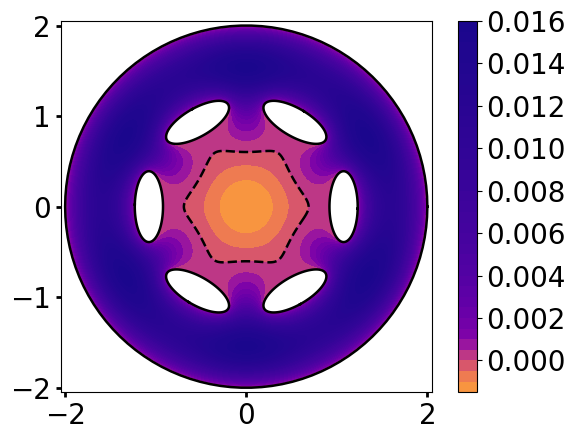

In [40]:
linthresh = 0.001 # Der Schwellenwert für die logarithmische Skalierung
norm = mcolors.SymLogNorm(linthresh=linthresh, vmin=vmin_sol, vmax=-vmin_sol)

fig, ax = plt.subplots()
plt.rcParams.update({'font.size':20})
ax.tick_params(axis='both', width=2)
cf = plt.tricontourf(triang, real_sol, cmap='plasma_r', norm=norm ,levels= 40, vmin=vmin_sol)
plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1.8)

plt.axis('square')
cbar = plt.colorbar(cf, label='')
cbar.ax.tick_params(labelsize=20)

plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)
for i in range(n_ellipses + 1):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:], color='black', linewidth = 1.8)

plt.tight_layout()

plt.savefig('Circle_six_ellipses_third_symlogplot.eps', format="eps")
plt.show()

In [28]:
# third eigenvalues

In [29]:
(3.82893875-1.28182489e-07j) * (3.82893875-1.28182489e-07j)

(14.660771951251546-9.816057984070975e-07j)